# CardioRitmo · Tamizaje de latidos anormales (DEV)

**Cliente:** CardioRitmo, fabricante de monitores Holter.
**Objetivo:** que el monitor señale los latidos anormales, de modo que el cardiólogo
revise únicamente esos.

**Especificaciones del cliente (en la prueba, con umbral de 0.5):**
- sensibilidad ≥ 95 % (de cada 100 latidos anormales, señalar al menos 95);
- especificidad ≥ 95 % (de cada 100 latidos normales, señalar como máximo 5);
- tamaño compatible con el monitor: **≤ 20,000 parámetros**.

Todas las decisiones se toman con el conjunto de **validación**; la prueba del cliente
se utiliza **una sola vez, al final**.

In [1]:
import os
import warnings

# TF en Windows no ve la GPU; Keras 3 sobre PyTorch sí
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import torch

# aviso interno e inofensivo de PyTorch al usar la GRU en GPU
warnings.filterwarnings("ignore", message="RNN module weights")

# resultados reproducibles en GPU (misma salida en cada ejecución)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
print(
    "Keras",
    keras.__version__,
    "| backend:",
    keras.backend.backend(),
    "| GPU:",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no",
)

Keras 3.15.1 | backend: torch | GPU: NVIDIA GeForce GTX 1660 SUPER


## 1. Datos

ECG5000 (archivo UCR): latidos de 140 puntos provenientes de **un solo paciente** con
insuficiencia cardiaca (base BIDMC, PhysioNet). La carga y la división se realizan
**exactamente** como se especifican en el enunciado.

In [2]:
# fmt: off
import pandas as pd
from sklearn.model_selection import train_test_split

ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")   # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")  # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# Con X_resto y y_resto armen su entrenamiento y su validación como quieran.

## 2. Exploración

Tamaño y balance de clases. A partir de este punto la exploración utiliza
**únicamente `X_resto`**, a fin de no inspeccionar la prueba.

In [3]:
print("Latidos totales:", X.shape[0], "| puntos por latido:", X.shape[1])
print("Valores faltantes:", int(np.isnan(X).sum()))
balance = pd.DataFrame(
    {
        "total": pd.Series(y).value_counts(),
        "resto": pd.Series(y_resto).value_counts(),
        "prueba": pd.Series(y_prueba).value_counts(),
    }
).rename(index={0: "normal (0)", 1: "anormal (1)"})
balance.loc["% anormal"] = (balance.loc["anormal (1)"] / balance.sum() * 100).round(1)
balance

Latidos totales: 4998 | puntos por latido: 140
Valores faltantes: 0


,total,resto,prueba
normal (0),2919.0,2335.0,584.0
anormal (1),2079.0,1663.0,416.0
% anormal,41.6,41.6,41.6


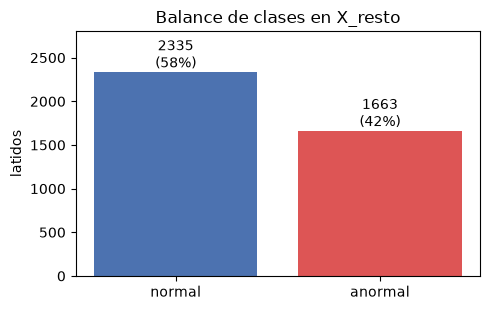

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
conteo = pd.Series(y_resto).value_counts().sort_index()
ax.bar(["normal", "anormal"], conteo.values, color=["#4C72B0", "#DD5555"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v}\n({v / conteo.sum():.0%})", ha="center", va="bottom")
ax.set_title("Balance de clases en X_resto")
ax.set_ylabel("latidos")
ax.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()

**Ejemplos:** cinco latidos de cada clase, seleccionados al azar.

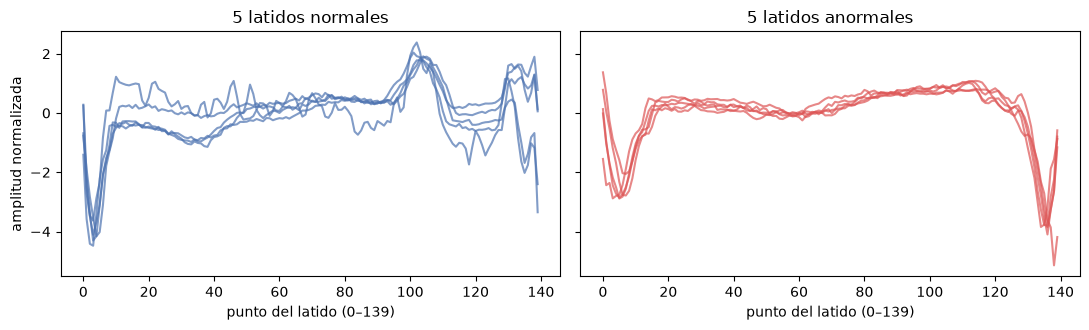

In [5]:
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, clase, nombre, color in zip(
    axes, [0, 1], ["normales", "anormales"], ["#4C72B0", "#DD5555"]
):
    for i in rng.choice(np.where(y_resto == clase)[0], 5, replace=False):
        ax.plot(X_resto[i], color=color, alpha=0.7)
    ax.set_title(f"5 latidos {nombre}")
    ax.set_xlabel("punto del latido (0–139)")
axes[0].set_ylabel("amplitud normalizada")
plt.tight_layout()
plt.show()

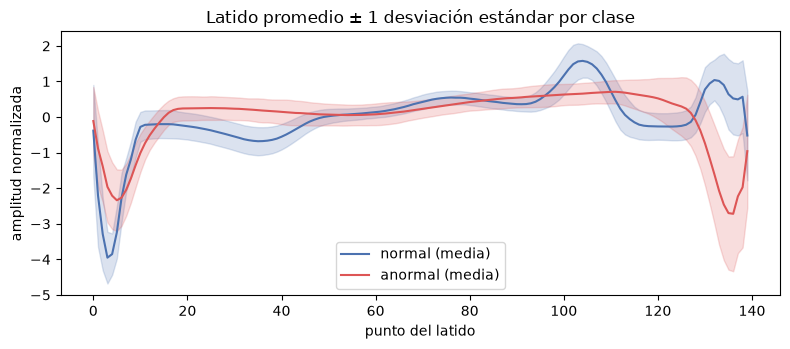

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for clase, nombre, color in [(0, "normal", "#4C72B0"), (1, "anormal", "#DD5555")]:
    m, s = X_resto[y_resto == clase].mean(0), X_resto[y_resto == clase].std(0)
    ax.plot(m, color=color, label=f"{nombre} (media)")
    ax.fill_between(range(140), m - s, m + s, color=color, alpha=0.2)
ax.set_title("Latido promedio ± 1 desviación estándar por clase")
ax.set_xlabel("punto del latido")
ax.set_ylabel("amplitud normalizada")
ax.legend()
plt.tight_layout()
plt.show()

**Observaciones:**
- El conjunto contiene 4,998 latidos de 140 puntos, sin valores faltantes. El 41.6 %
  son anormales, por lo que las clases están razonablemente balanceadas.
- Las dos clases se distinguen con claridad en su forma promedio, sobre todo al final
  del latido, lo que sugiere que un modelo pequeño puede ser suficiente.
- El latido anormal típico carece del pico cercano al punto 105 y desciende al final
  (puntos 125–139). En esa zona su banda de ±1 desviación estándar es más amplia, por
  lo que se espera que los anormales de forma atípica concentren los errores.
- **Limitación principal:** todos los datos provienen de un solo paciente; lo que el
  modelo aprenda describe *sus* latidos y no necesariamente los de otras personas.

## 3. Preparación

**División.** La prueba ya se encuentra apartada. De `X_resto` se extrae un 20 %
estratificado para **validación**, con el cual se eligen la arquitectura, el número de
épocas y el modelo final. La prueba no se vuelve a utilizar hasta la sección de
resultados.

In [7]:
X_ent, X_val, y_ent, y_val = train_test_split(
    X_resto, y_resto, test_size=0.2, stratify=y_resto, random_state=SEMILLA
)
pd.DataFrame(
    {
        "latidos": [len(y_ent), len(y_val), len(y_prueba)],
        "% anormal": [y_ent.mean() * 100, y_val.mean() * 100, y_prueba.mean() * 100],
    },
    index=["entrenamiento", "validación", "prueba (cerrada)"],
).round(1)

,latidos,% anormal
entrenamiento,3198,41.6
validación,800,41.6
prueba (cerrada),1000,41.6


**Transformación.** Cada latido ya viene normalizado (z-score por latido: media 0 y
desviación estándar 1). Esta normalización emplea solo los 140 puntos del propio
latido, por lo que no combina información entre latidos ni introduce fuga desde la
prueba. Se verifica a continuación y no se agrega otro escalado, ya que un escalador
ajustado sobre datos de validación o prueba constituiría una fuente de fuga.

Para las redes convolucionales y recurrentes, cada latido se representa como una
secuencia de 140 pasos con 1 canal, con forma `(latidos, 140, 1)`.

In [8]:
medias, desv = X_ent.mean(axis=1), X_ent.std(axis=1)
print(f"media por latido: [{medias.min():.4f}, {medias.max():.4f}]")
print(f"desv. por latido: [{desv.min():.4f}, {desv.max():.4f}]")

X_ent_seq, X_val_seq = X_ent[..., None], X_val[..., None]
print("forma para Conv1D/RNN:", X_ent_seq.shape, X_val_seq.shape)

media por latido: [-0.0000, 0.0000]
desv. por latido: [0.9964, 0.9964]
forma para Conv1D/RNN: (3198, 140, 1) (800, 140, 1)


## 4. Métricas del cliente

Las especificaciones se expresan en **sensibilidad** (proporción de latidos anormales
que el modelo señala) y **especificidad** (proporción de latidos normales que el
modelo no señala), con umbral de 0.5. Se reporta además el **AUC**, que no depende
del umbral. Una única función evalúa todos los modelos con el mismo criterio.

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score

UMBRAL = 0.5
META = 0.95
MAX_PARAMETROS = 20_000


def metricas(y_real, prob, umbral=UMBRAL):
    """Sensibilidad, especificidad y AUC de probabilidades de 'anormal'."""
    vn, fp, fn, vp = confusion_matrix(y_real, prob >= umbral, labels=[0, 1]).ravel()
    return {
        "sensibilidad": vp / (vp + fn),
        "especificidad": vn / (vn + fp),
        "auc": roc_auc_score(y_real, prob),
    }


def cumple(m, parametros):
    return bool(
        m["sensibilidad"] >= META
        and m["especificidad"] >= META
        and parametros <= MAX_PARAMETROS
    )


# autoverificación: un clasificador perfecto da 1, 1, 1
assert metricas(np.array([0, 1, 1]), np.array([0.1, 0.9, 0.6])) == {
    "sensibilidad": 1.0,
    "especificidad": 1.0,
    "auc": 1.0,
}

## 5. Línea base trivial

La línea base predice siempre la clase más frecuente (**normal**) y asigna como
probabilidad la proporción de anormales observada en entrenamiento. No tiene
parámetros entrenables y establece el desempeño mínimo que cualquier modelo debe
superar.

In [10]:
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="prior").fit(X_ent, y_ent)
prob_base_val = base.predict_proba(X_val)[:, 1]

validacion = {}  # aquí se acumulan las métricas en validación de cada modelo
validacion["Línea base (clase mayoritaria)"] = metricas(y_val, prob_base_val) | {
    "parametros": 0
}
pd.DataFrame(validacion).T

,sensibilidad,especificidad,auc,parametros
Línea base (clase mayoritaria),0.0,1.0,0.5,0.0


La línea base **no señala ningún latido** (sensibilidad de 0 %). Su especificidad es
perfecta, pero carece de utilidad para el cliente, y su AUC de 0.5 equivale a una
asignación aleatoria.

## 6. Modelos

Todos los modelos se entrenan con el mismo procedimiento, para que la comparación sea
justa:
- pérdida de entropía cruzada binaria y optimizador Adam;
- hasta 150 épocas con **parada temprana** sobre la pérdida de validación (paciencia
  de 15), recuperando los mejores pesos;
- umbral fijo en 0.5, como lo establece el cliente; no se ajusta.

Dado que la validación determina el momento de parada, sus métricas son ligeramente
optimistas; la evaluación definitiva corresponde a la prueba.

In [11]:
from keras import layers


def entrenar(modelo, X_e, X_v, epocas=150, lote=64):
    """Entrena con parada temprana sobre validación y registra sus métricas."""
    keras.utils.set_random_seed(SEMILLA)
    modelo.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    historia = modelo.fit(
        X_e,
        y_ent,
        validation_data=(X_v, y_val),
        epochs=epocas,
        batch_size=lote,
        callbacks=[
            keras.callbacks.EarlyStopping(
                patience=15, restore_best_weights=True, monitor="val_loss"
            )
        ],
        verbose=0,
    )
    parametros = modelo.count_params()
    prob_val = modelo.predict(X_v, verbose=0).ravel()
    validacion[modelo.name] = metricas(y_val, prob_val) | {"parametros": parametros}
    print(
        f"{modelo.name}: {parametros:,} parámetros | "
        f"{len(historia.history['loss'])} épocas | cumple el límite de tamaño: "
        f"{parametros <= MAX_PARAMETROS}"
    )
    return historia


def curvas(historia, titulo):
    _, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for ax, clave, nombre in zip(axes, ["loss", "auc"], ["pérdida", "AUC"]):
        ax.plot(historia.history[clave], label="entrenamiento")
        ax.plot(historia.history[f"val_{clave}"], label="validación")
        ax.set_title(f"{titulo}: {nombre}")
        ax.set_xlabel("época")
        ax.legend()
    plt.tight_layout()
    plt.show()

### 6.1 MLP (red densa)

Es el modelo más sencillo: trata los 140 puntos como 140 variables independientes, sin
considerar que forman una secuencia. Consta de dos capas ocultas pequeñas con
*dropout* para reducir el sobreajuste a los 3,198 latidos de entrenamiento.

In [12]:
mlp = keras.Sequential(
    [
        keras.Input(shape=(140,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="MLP",
)
mlp.summary()

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

MLP: 11,137 parámetros | 21 épocas | cumple el límite de tamaño: True


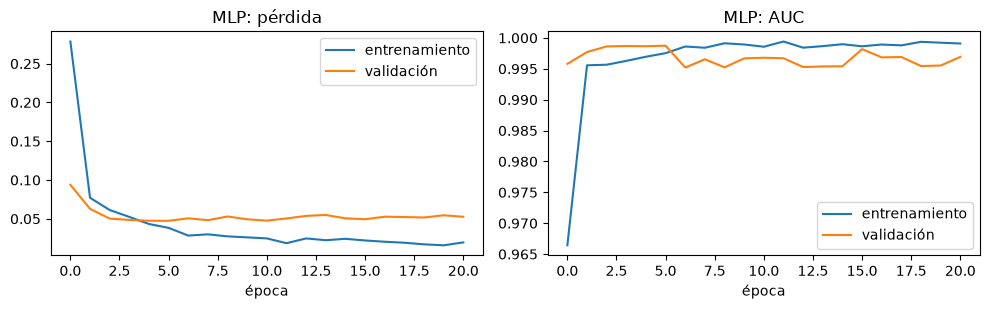

,sensibilidad,especificidad,auc,parametros
Línea base (clase mayoritaria),0.000000,1.000000,0.500000,0.0
MLP,0.972973,0.991435,0.998759,11137.0


In [13]:
historia_mlp = entrenar(mlp, X_ent, X_val)
curvas(historia_mlp, "MLP")
pd.DataFrame(validacion).T

**Resultados del MLP.** Con 11,137 parámetros (55 % del límite), el modelo supera
ambas metas en validación: sensibilidad de 97.3 % y especificidad de 99.1 %, con AUC
de 0.999. La pérdida de validación se estabiliza alrededor de la época 6 y la parada
temprana detiene el entrenamiento en la época 21, por lo que no se requiere un modelo
más grande. No obstante, se evalúan también modelos que **sí consideran la estructura
secuencial** (Conv1D y GRU), ya que un MLP es sensible a desplazamientos temporales
del latido, frecuentes en un registro Holter real.

### 6.2 Conv1D (red convolucional)

Las convoluciones recorren el latido con filtros pequeños que detectan patrones
locales (picos, pendientes) sin importar su posición exacta. Se apilan tres bloques
convolucionales con *max pooling*, que reducen la secuencia de 140 a 17 pasos, y un
promedio global antes de la capa de salida. Este diseño reutiliza los mismos filtros
a lo largo de todo el latido, por lo que requiere pocos parámetros.

In [14]:
conv = keras.Sequential(
    [
        keras.Input(shape=(140, 1)),
        layers.Conv1D(16, 7, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="Conv1D",
)
conv.summary()

Model: "Conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 140, 16)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 70, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 70, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 35, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 35, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 17, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,369 (24.88 KB)

 Trainable params: 6,369 (24.88 KB)

 Non-trainable params: 0 (0.00 B)

Conv1D: 6,369 parámetros | 89 épocas | cumple el límite de tamaño: True


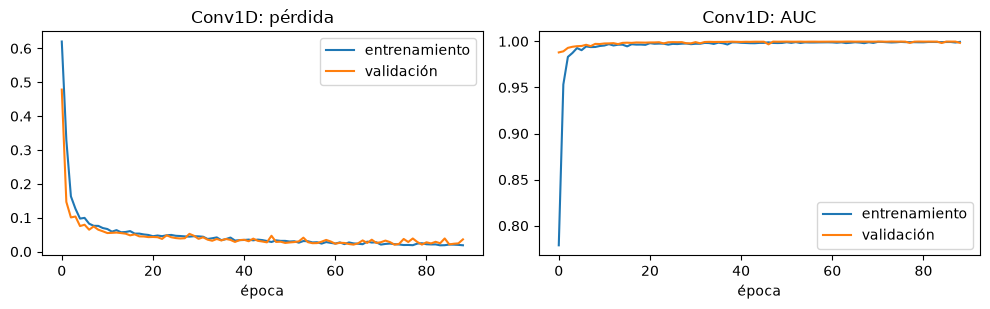

In [15]:
historia_conv = entrenar(conv, X_ent_seq, X_val_seq)
curvas(historia_conv, "Conv1D")

### 6.3 GRU (red recurrente)

La GRU lee el latido punto por punto y mantiene un estado interno que resume lo
observado hasta ese momento; la clasificación se basa en el estado final, tras leer
los 140 puntos. Se emplea una sola capa de 32 unidades, suficiente para el tamaño del
conjunto y muy por debajo del límite de parámetros.

In [16]:
gru = keras.Sequential(
    [
        keras.Input(shape=(140, 1)),
        layers.GRU(32),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="GRU",
)
gru.summary()

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

GRU: 3,393 parámetros | 96 épocas | cumple el límite de tamaño: True


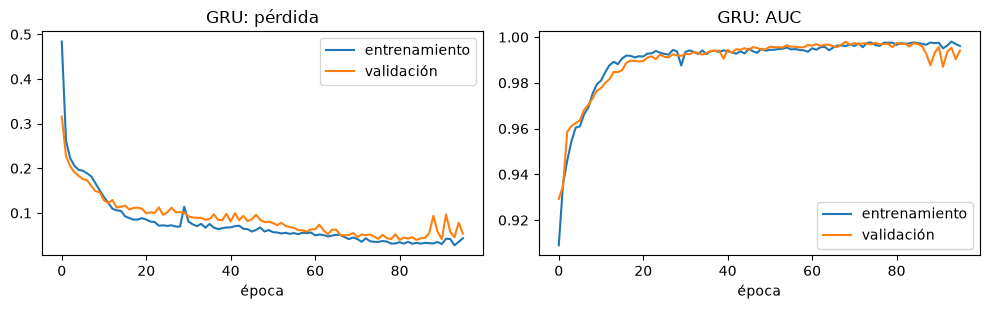

In [17]:
historia_gru = entrenar(gru, X_ent_seq, X_val_seq)
curvas(historia_gru, "GRU")

### 6.4 Comparación en validación

Tabla con los cuatro modelos evaluados sobre los 800 latidos de validación. La prueba
del cliente sigue sin utilizarse.

In [18]:
tabla_val = pd.DataFrame(validacion).T
tabla_val["parametros"] = tabla_val["parametros"].astype(int)
tabla_val["cumple en validación"] = [
    cumple(m, m["parametros"]) for m in validacion.values()
]
tabla_val.round(4)

,sensibilidad,especificidad,auc,parametros,cumple en validación
Línea base (clase mayoritaria),0.000,1.0000,0.5000,0,False
MLP,0.973,0.9914,0.9988,11137,True
Conv1D,0.997,0.9914,0.9998,6369,True
GRU,0.970,1.0000,0.9975,3393,True


**Análisis de la comparación.** Los tres modelos entrenados cumplen ambas metas en
validación y ocupan entre el 17 % y el 56 % del límite de parámetros. Sobre los 333
latidos anormales y 467 normales de validación:
- **Conv1D** (6,369 parámetros) omite 1 latido anormal y señala 4 normales; obtiene la
  mayor sensibilidad (99.7 %) y el mayor AUC (0.9998).
- **MLP** (11,137 parámetros) omite 9 anormales y señala 4 normales.
- **GRU** (3,393 parámetros) no señala ningún normal, pero omite 10 anormales; su
  sensibilidad de 97.0 % es la más cercana a la meta. Además, es la más lenta de
  entrenar (96 épocas, lectura secuencial de 140 pasos).

Para un tamizaje, omitir un latido anormal es más grave que enviar uno normal a revisión,
por lo que la sensibilidad es el criterio prioritario, siempre que se respete la
especificidad. Con base en la validación, la **Conv1D** es la candidata principal; la
selección final y su verificación en la prueba se presentan en la siguiente sección.

## 7. Selección del modelo y evaluación en la prueba

**Selección (con validación, antes de abrir la prueba).** Se elige la **Conv1D**: es
el modelo con mayor sensibilidad (99.7 %) y mayor AUC (0.9998) en validación, cumple
la especificidad con margen (99.1 %) y usa 6,369 parámetros, el 32 % del límite. La
elección queda fijada en la siguiente celda; el resultado de la prueba no la modifica.

In [19]:
ELEGIDO = "Conv1D"
modelos = {"MLP": (mlp, X_prueba), "Conv1D": (conv, X_prueba[..., None])}
modelos["GRU"] = (gru, X_prueba[..., None])
tipos = {"MLP": "densa", "Conv1D": "convolucional", "GRU": "recurrente"}

**Evaluación única en la prueba del cliente** (1,000 latidos: 416 anormales y 584
normales), con umbral de 0.5. Esta es la única vez que se utiliza `X_prueba`.

Nota sobre la columna `tipo`: la lista del enunciado no incluye una categoría para
redes densas, por lo que el MLP se registra como `densa` en lugar de forzarlo en una
categoría que no le corresponde.

In [20]:
filas = [
    {
        "modelo": "Línea base (clase mayoritaria)",
        "tipo": "linea base",
        "parametros": 0,
        **metricas(y_prueba, base.predict_proba(X_prueba)[:, 1]),
    }
]
prob_prueba = {}
for nombre, (modelo, X_p) in modelos.items():
    prob_prueba[nombre] = modelo.predict(X_p, verbose=0).ravel()
    filas.append(
        {
            "modelo": nombre,
            "tipo": tipos[nombre],
            "parametros": modelo.count_params(),
            **metricas(y_prueba, prob_prueba[nombre]),
        }
    )

resultados = pd.DataFrame(filas)
resultados["cumple"] = [cumple(f, f["parametros"]) for f in filas]
resultados["elegido"] = resultados["modelo"] == ELEGIDO
resultados.to_csv("resultados_ecg.csv", index=False)
resultados.round(4)

,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (clase mayoritaria),linea base,0,0.0000,1.0000,0.5000,False,False
1,MLP,densa,11137,0.9832,1.0000,0.9985,True,False
2,Conv1D,convolucional,6369,0.9928,0.9949,0.9991,True,True
3,GRU,recurrente,3393,0.9688,1.0000,0.9961,True,False


**Desempeño del modelo elegido en la prueba**, en los términos del cliente:

De 416 latidos anormales, el modelo señala 413 y omite 3.
De 584 latidos normales, señala 3 como anormales por error.
De cada 100 anormales señala 99.3.
De cada 100 normales señala 0.5 por error.


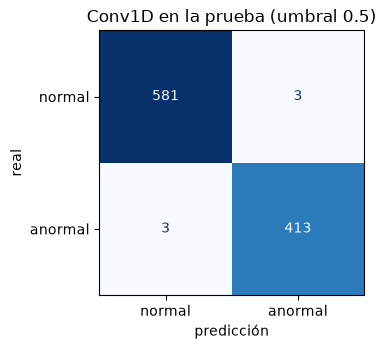

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

pred_elegido = (prob_prueba[ELEGIDO] >= UMBRAL).astype(int)
vn, fp, fn, vp = confusion_matrix(y_prueba, pred_elegido).ravel()
print(f"De {vp + fn} latidos anormales, el modelo señala {vp} y omite {fn}.")
print(f"De {vn + fp} latidos normales, señala {fp} como anormales por error.")
print(f"De cada 100 anormales señala {vp / (vp + fn) * 100:.1f}.")
print(f"De cada 100 normales señala {fp / (vn + fp) * 100:.1f} por error.")

_, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay.from_predictions(
    y_prueba,
    pred_elegido,
    display_labels=["normal", "anormal"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"{ELEGIDO} en la prueba (umbral 0.5)")
ax.set_xlabel("predicción")
ax.set_ylabel("real")
plt.tight_layout()
plt.show()

**Resultado en la prueba.** Los tres modelos entrenados cumplen las especificaciones
del cliente; la línea base no. El modelo elegido, la **Conv1D**, obtiene:
- **sensibilidad de 99.3 %**: de 416 latidos anormales señala 413 y omite 3 (meta: ≥ 95 %);
- **especificidad de 99.5 %**: de 584 latidos normales señala 3 por error (meta: ≥ 95 %);
- **AUC de 0.9991** con **6,369 parámetros** (meta: ≤ 20,000).

Los resultados en la prueba son consistentes con los de validación (99.7 % y 99.1 %), lo
que indica que la selección no se sobreajustó a la validación. El MLP alcanza una
especificidad perfecta en la prueba, pero omite 7 anormales frente a 3 de la Conv1D; la
GRU omite 13. Dado que en un tamizaje un latido anormal omitido no llega al cardiólogo,
se mantiene la Conv1D, seleccionada previamente con validación.

## 8. Modelo guardado

El modelo elegido se guarda en `modelo/modelo_ecg.keras`. Para verificar el archivo,
se vuelve a cargar y se comprueba que produce las mismas probabilidades en la prueba.

In [22]:
os.makedirs("modelo", exist_ok=True)
conv.save("modelo/modelo_ecg.keras")

recargado = keras.models.load_model("modelo/modelo_ecg.keras")
prob_recargado = recargado.predict(X_prueba[..., None], verbose=0).ravel()
assert np.allclose(prob_recargado, prob_prueba[ELEGIDO], atol=1e-5)
tamano_kb = os.path.getsize("modelo/modelo_ecg.keras") / 1024
print(
    f"modelo/modelo_ecg.keras: {tamano_kb:.0f} KB, {recargado.count_params():,} parámetros"
)
print("Verificación: el modelo recargado reproduce las probabilidades de la prueba.")

modelo/modelo_ecg.keras: 121 KB, 6,369 parámetros
Verificación: el modelo recargado reproduce las probabilidades de la prueba.


## 9. Justificación de la elección

Se elige la **Conv1D** por las siguientes razones, todas establecidas con validación
y confirmadas en la prueba:

1. **Prioriza lo que más le importa al cliente.** En un tamizaje, un latido anormal
   omitido no llega al cardiólogo, mientras que un normal señalado solo le cuesta una
   revisión adicional. La Conv1D obtuvo la mayor sensibilidad en validación (99.7 %) y
   en la prueba omite 3 anormales, frente a 7 del MLP y 13 de la GRU.
2. **Cumple la especificidad con margen**: 99.5 % en la prueba frente a la meta de 95 %.
3. **Cabe con holgura en el monitor**: 6,369 parámetros (32 % del límite) y un
   archivo de 121 KB.
4. **Es adecuada para señales.** Sus filtros detectan el mismo patrón en cualquier
   posición del latido, lo que la hace menos sensible que el MLP a pequeños
   desplazamientos temporales; esto se evalúa en la sección 11.
5. **Es eficiente**: a diferencia de la GRU, no procesa el latido paso por paso, por lo
   que su inferencia es más rápida en un dispositivo con recursos limitados.

## 10. Análisis de errores

Se listan todos los errores del modelo elegido en la prueba y se analizan tres: el
anormal omitido con mayor confianza, el normal señalado con mayor confianza y el
error restante más cercano al umbral.

In [23]:
prob_e = prob_prueba[ELEGIDO]
errores = pd.DataFrame(
    {
        "indice": np.where(pred_elegido != y_prueba)[0],
    }
)
errores["real"] = np.where(y_prueba[errores["indice"]] == 1, "anormal", "normal")
errores["probabilidad de anormal"] = prob_e[errores["indice"]].round(4)
errores["tipo de error"] = np.where(
    errores["real"] == "anormal", "anormal omitido", "normal señalado"
)
errores["distancia al umbral"] = (errores["probabilidad de anormal"] - UMBRAL).abs()
errores = errores.sort_values("distancia al umbral", ascending=False)
errores

,indice,real,probabilidad de anormal,tipo de error,distancia al umbral
1,135,anormal,0.0033,anormal omitido,0.4967
3,160,anormal,0.0251,anormal omitido,0.4749
2,144,normal,0.9496,normal señalado,0.4496
0,75,normal,0.6474,normal señalado,0.1474
5,339,anormal,0.3679,anormal omitido,0.1321
4,232,normal,0.5524,normal señalado,0.0524


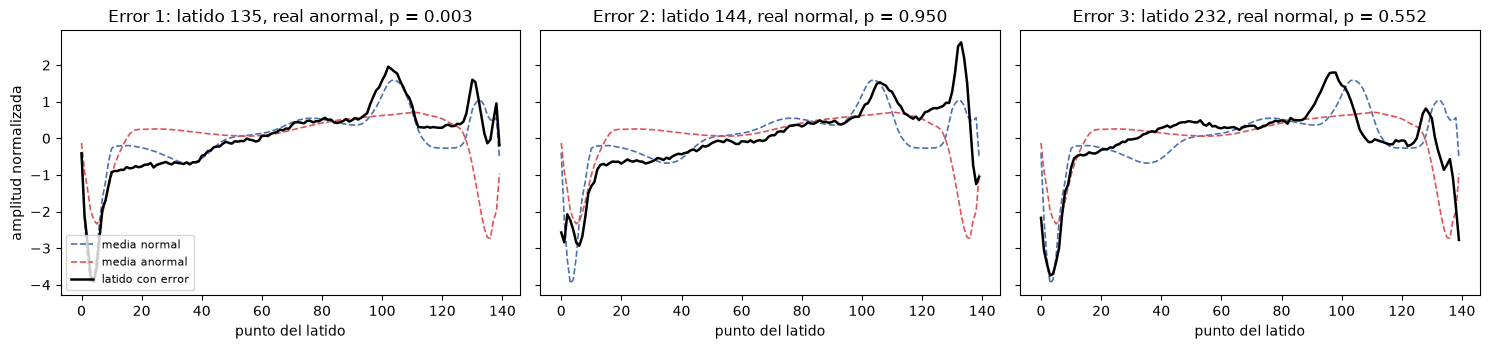

In [24]:
omitidos = errores[errores["tipo de error"] == "anormal omitido"]
senalados = errores[errores["tipo de error"] == "normal señalado"]
elegidos = [omitidos["indice"].iloc[0], senalados["indice"].iloc[0]]
restantes = errores[~errores["indice"].isin(elegidos)]
elegidos.append(restantes.sort_values("distancia al umbral")["indice"].iloc[0])

media_normal = X_ent[y_ent == 0].mean(axis=0)
media_anormal = X_ent[y_ent == 1].mean(axis=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for k, (ax, i) in enumerate(zip(axes, elegidos), start=1):
    real = "anormal" if y_prueba[i] == 1 else "normal"
    ax.plot(media_normal, color="#4C72B0", ls="--", lw=1.2, label="media normal")
    ax.plot(media_anormal, color="#DD5555", ls="--", lw=1.2, label="media anormal")
    ax.plot(X_prueba[i], color="black", lw=1.8, label="latido con error")
    ax.set_title(f"Error {k}: latido {i}, real {real}, p = {prob_e[i]:.3f}")
    ax.set_xlabel("punto del latido")
axes[0].set_ylabel("amplitud normalizada")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Análisis de los tres errores.** De los 1,000 latidos de la prueba, el modelo comete 6
errores: 3 anormales omitidos y 3 normales señalados.

1. **Latido 135: anormal omitido con alta confianza (p = 0.003).** Su forma es
   prácticamente la del latido normal promedio: deflexión inicial profunda, pico cerca
   del punto 103 y un segundo pico cerca del 130, sin la caída final característica de
   los anormales. Con los 140 puntos del latido no hay evidencia de la anomalía. Puede
   tratarse de una alteración que no se refleja en la forma, por ejemplo un latido
   prematuro, cuya anomalía está en el tiempo respecto al latido anterior y no en la
   morfología (el modelo recibe cada latido aislado, sin esa información), o bien de un
   error de etiqueta. Ningún cambio de umbral corrige este error. Junto con el latido 160
   (p = 0.025), son los dos casos más preocupantes para el cliente.
2. **Latido 144: normal señalado con alta confianza (p = 0.950).** El inicio es poco
   profundo (≈ −2.9 frente a −4 del promedio normal) y al final presenta un pico alto
   cerca del punto 133 seguido de una caída pronunciada, parecida a la caída final de
   los anormales. El modelo reacciona a esa zona final, que es la que más separa a las
   clases (sección 2). Para el cliente, el costo es una revisión innecesaria.
3. **Latido 232: normal señalado cerca del umbral (p = 0.552).** El pico principal
   aparece antes de lo habitual (punto ≈ 97 frente a 103), el segundo pico es casi
   inexistente y el latido termina descendiendo hasta −2.8, de nuevo como un anormal.
   Es un caso ambiguo; el modelo lo señala apenas por encima del umbral, lo cual es el
   comportamiento deseable en un tamizaje: ante la duda, se envía a revisión.

**Conclusión.** Los errores se concentran en latidos cuya forma contradice su etiqueta,
sobre todo en la zona final (puntos 120–139). La separación de probabilidades es muy
clara (solo 6 de 1,000 latidos quedan entre 0.2 y 0.8), por lo que mover el umbral
apenas cambiaría el resultado: los anormales omitidos con confianza no se recuperan
ajustándolo, y el cliente fijó el umbral en 0.5.

Como referencia, la distribución de probabilidades del modelo en la prueba muestra qué
tan separadas quedan las clases y dónde se ubican los errores respecto al umbral.

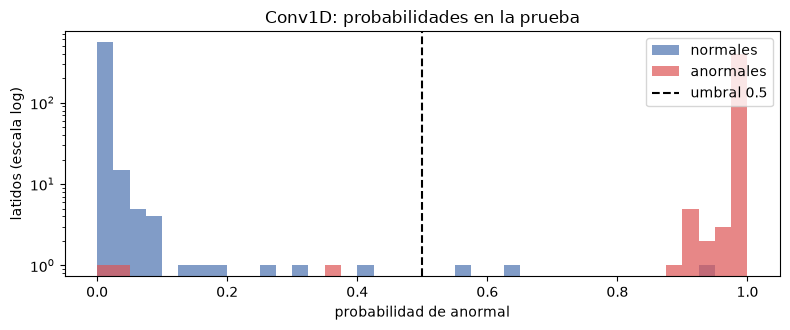

Latidos con probabilidad entre 0.2 y 0.8: 6 de 1000


In [25]:
_, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 41)
ax.hist(prob_e[y_prueba == 0], bins=bins, color="#4C72B0", alpha=0.7, label="normales")
ax.hist(prob_e[y_prueba == 1], bins=bins, color="#DD5555", alpha=0.7, label="anormales")
ax.axvline(UMBRAL, color="black", ls="--", label="umbral 0.5")
ax.set_yscale("log")
ax.set_xlabel("probabilidad de anormal")
ax.set_ylabel("latidos (escala log)")
ax.set_title(f"{ELEGIDO}: probabilidades en la prueba")
ax.legend()
plt.tight_layout()
plt.show()
cerca = ((prob_e > 0.2) & (prob_e < 0.8)).sum()
print(f"Latidos con probabilidad entre 0.2 y 0.8: {cerca} de {len(prob_e)}")